 ## 1. Setup
We import the usual data science stack:
* `pandas` / `numpy` → data manipulation,
* `matplotlib` / `seaborn` → plots,

In [1]:
from pathlib import Path
import hashlib

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_style("whitegrid")

project_dir = Path.cwd()
if not (project_dir / "data" / "raw").is_dir():
    project_dir = project_dir.parent

data_dir = project_dir / "data" / "raw"
train_raw = pd.read_csv(data_dir / "train.csv", index_col="ID")
clients_raw = pd.read_csv(data_dir / "clientes.csv")


train = train_raw.copy()
clients = clients_raw.copy()

## 2. Data Import


In [2]:
print(f"Train: {train.shape[0]:,} linhas e {train.shape[1]} colunas (sem o ID)")
print(f"Clientes: {clients.shape[0]:,} linhas e {clients.shape[1]} colunas")
print("Exemplos de compras:")
display(train.head())
print("Exemplos da tabela auxiliar:")
display(clients.head())

print("\nEstrutura do treino:")
train.info()
print("\nEstrutura dos clientes:")
clients.info()
display(train.dtypes.value_counts().rename("Número de colunas por tipo"))



Train: 6,534 linhas e 38 colunas (sem o ID)
Clientes: 1,143 linhas e 13 colunas
Exemplos de compras:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


Exemplos da tabela auxiliar:


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



Estrutura do treino:
<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_d

float64    29
str         7
int64       2
Name: Número de colunas por tipo, dtype: int64

**First observations from `info()`:**
* `N_Detalhes` e `invoice_count_current_purchase`  encontram-se em formato float, será um possível erro?
* Algumas rows têm **missing values** nas columns `commercial_region`, `municipality`, `city`e `postal_area`


### Descrição dos datasets utilizados nesta etapa

Nesta etapa, a exploração utiliza apenas `train.csv` e a tabela auxiliar `clientes.csv`.

| Dataset | Linhas | Colunas no CSV | Conteúdo |
|---|---:|---:|---|
| `train.csv` | 6 534 | 39 | Compras com características e variável alvo, para exploração e desenvolvimento dos modelos. |
| `clientes.csv` | 1 143 | 13 | Informação adicional por cliente, associável através de `customer_id`. |

#### Variáveis de `train.csv`

As tabelas seguintes descrevem as 39 colunas do ficheiro de treino, incluindo a variável alvo `repeat_purchase_90d` e o identificador `ID`. Neste notebook, `ID` é utilizado como índice, pelo que o DataFrame apresenta 38 colunas.


##### Identificação e variável alvo

| Variável | Descrição |
|---|---|
| `ID` | Identificador da observação de compra; permite associar cada previsão à linha correspondente. No notebook, é usado como índice. |
| `customer_id` | Identificador do cliente e chave para associar a informação de clientes.csv. Pode repetir-se em compras diferentes. |
| `purchase_date` | Data associada à compra, armazenada como texto no CSV. |
| `repeat_purchase_90d` | Variável alvo: 1 indica recompra nos 90 dias seguintes e 0 indica ausência de recompra nesse período. Existe apenas em train.csv. |

##### Valores da compra atual

| Variável | Descrição |
|---|---|
| `Total a Pagar` | Montante total a pagar pela compra. |
| `Total Bruto` | Valor bruto da compra. |
| `Total Liquido` | Valor líquido da compra. |
| `Total Imp_` | Montante de impostos associado à compra. |
| `Total Portes` | Montante dos portes associado à compra. |
| `Total Desc_ Global` | Montante do desconto global da compra. |
| `Total Desc_ Linha` | Montante dos descontos aplicados às linhas da compra. |
| `Custo` | Custo registado para a compra; a definição contabilística deve ser confirmada. |

##### Dimensão e contexto da compra

| Variável | Descrição |
|---|---|
| `N_ Detalhes` | Número de detalhes ou linhas da compra; não equivale necessariamente à quantidade de unidades compradas. |
| `invoice_count_current_purchase` | Número de faturas associado à compra atual. |
| `payment_type` | Categoria do tipo de pagamento. |
| `salesperson` | Categoria que identifica o vendedor. |
| `commercial_zone` | Zona comercial associada à compra. |
| `transport_method` | Modalidade de transporte associada à compra. |
| `warehouse` | Armazém associado à compra. |
| `document_series` | Série do documento associado à compra. |

##### Histórico do cliente

| Variável | Descrição |
|---|---|
| `days_since_previous_purchase` | Número de dias desde a compra anterior. |
| `customer_tenure_days` | Antiguidade do cliente em dias no momento da compra; a data de referência inicial deve ser confirmada. |
| `prior_purchase_count` | Número de compras anteriores do cliente. |
| `prior_total_spend` | Montante total gasto anteriormente pelo cliente. |
| `prior_mean_purchase_value` | Valor médio das compras anteriores. |
| `prior_std_purchase_value` | Desvio-padrão dos valores das compras anteriores. |
| `prior_min_purchase_value` | Menor valor de compra no histórico anterior. |
| `prior_max_purchase_value` | Maior valor de compra no histórico anterior. |
| `prior_mean_gap_days` | Média dos intervalos, em dias, entre compras anteriores. |
| `prior_std_gap_days` | Desvio-padrão dos intervalos, em dias, entre compras anteriores. |

##### Atividade em janelas temporais

| Variável | Descrição |
|---|---|
| `purchase_count_30d` | Número de compras na janela histórica de 30 dias. |
| `spend_30d` | Montante gasto na janela histórica de 30 dias. |
| `purchase_count_90d` | Número de compras na janela histórica de 90 dias. |
| `spend_90d` | Montante gasto na janela histórica de 90 dias. |
| `purchase_count_180d` | Número de compras na janela histórica de 180 dias. |
| `spend_180d` | Montante gasto na janela histórica de 180 dias. |
| `purchase_count_365d` | Número de compras na janela histórica de 365 dias. |
| `spend_365d` | Montante gasto na janela histórica de 365 dias. |

##### Variável numérica adicional

| Variável | Descrição |
|---|---|
| `random_noise` | Variável numérica cujo nome sugere ruído. A sua utilidade deve ser avaliada nos dados, sem assumir que tem valor preditivo. |

#### Variáveis de `clientes.csv`

| Variável | Descrição |
|---|---|
| `customer_id` | Identificador do cliente, usado para associar esta tabela às compras. |
| `country_or_region` | País ou região do cliente. |
| `commercial_region` | Região comercial do cliente. |
| `island` | Ilha associada ao cliente; um valor em falta não permite, por si só, concluir que o campo não se aplica. |
| `municipality` | Município associado ao cliente. |
| `city` | Cidade associada ao cliente. |
| `postal_area` | Área postal associada ao cliente. |
| `postal_code` | Código postal; é uma categoria geográfica, não uma quantidade. |
| `street` | Rua associada ao cliente. |
| `address` | Morada do cliente. |
| `customer_type` | Campo destinado ao tipo de cliente. No ficheiro atual, todos os valores estão em falta. |
| `company_name` | Nome da empresa cliente. |
| `customer_since_year` | Ano de início da relação com o cliente, segundo o nome do campo. |

Para uma melhor observação futura dos dados, vamos organizar as 13 variáveis do `clients.csv`em familias de acordo com a descrição do data set.


In [3]:
var_groups = {
    "Identifier":   ["customer_id"],
    "Location":     ["country_or_region", "island", "municipality", "city",
                        "postal_area", "postal_code", "street", "address"],
    "Customer Profile ": ["commercial_region", "customer_type",
                          "company_name", "customer_since_year"],
}

pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()],
    columns=["Group", "Number of Variables", "Variables"],
)

,Group,Number of Variables,Variables
0,Identifier,1,customer_id
1,Location,8,"country_or_region, island, municipality, city,..."
2,Customer Profile,4,"commercial_region, customer_type, company_name..."


In [4]:
display(clients.head())

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


## 3. Data quality assessment of `clients.csv`
Before changing anything, we first **diagnose** the problems. This way we know exactly what we are fixing (and how many rows are affected).


### 3.1 Duplicates

In [5]:
duplicated_customer_id= clients_raw["customer_id"].duplicated().sum()
duplicated_rows_clients= clients_raw.duplicated().sum()

print(f"Duplicated customer_id in clients.csv:{duplicated_customer_id}")
print(f"Fully duplicated rows in clients.csv:{duplicated_rows_clients}")

Duplicated customer_id in clients.csv:0
Fully duplicated rows in clients.csv:0


In [6]:
#Confirmação que customer_id não se encontra no indice.

print("customer_id" in clients_raw.columns)   # deve dar True

True


In [7]:
#Confirmação de que não existem ID's em falta 

print(clients_raw["customer_id"].isna().sum())   # deve dar 0

0


Não foram encontrados customer_id duplicados nem linhas totalmente duplicadas em clients.csv. A chave é única, pelo que a tabela pode ser juntada às compras sem multiplicar observações.

In [8]:
chave = ["company_name", "address", "postal_code"]
com_chave = clients_raw.dropna(subset=chave)  

verificacao_chaves = pd.Series({
    "Same clients with different customer_id": clients_raw.drop(columns="customer_id").duplicated().sum(), #representam o mesmo registo de compra mas com customer_id's diferentes
    "Duplicated rows sharing company_name + address + postal_code": com_chave.duplicated(subset=chave).sum(), #repetições que descrevem a mesma entidade
})
display(verificacao_chaves.to_frame("Result"))



,Result
Same clients with different customer_id,0
Duplicated rows sharing company_name + address + postal_code,1


We tested duplicates at several levels. No rows are identical except for customer_id (0), so there are no exact copies registered under a new ID. One pair of rows shares the same company_name, address and postal_code; this was inspected manually and [kept as two distinct customers because ... / treated as the same customer because ...].

In [9]:
#perceber qual o par duplicado com as mesmas customer characteristics
chave = ["company_name", "address", "postal_code"]
com_chave = clients_raw.dropna(subset=chave)

par = com_chave[com_chave.duplicated(subset=chave, keep=False)].sort_values("customer_id")
display(par.T)   # lado a lado, mais fácil de comparar

# Em que colunas as duas linhas diferem?
print((par.nunique(dropna=False) > 1).loc[lambda s: s])

# Cada um dos dois clientes tem compras no train?
print(train[train["customer_id"].isin(par["customer_id"])].groupby("customer_id").size())





,390,391
customer_id,255774,714679
country_or_region,Country CT10: Land of The Final Version,Country CT10: Land of The Final Version
commercial_region,Region RG17: We Will See Later,Region RG17: We Will See Later
island,Island IS7: The Pivot Archipelago,Island IS7: The Pivot Archipelago
municipality,Municipality MU12: Council of Last Minute Edits,Municipality MU12: Council of Last Minute Edits
city,NaN,NaN
postal_area,Postal area PA254: Hidden Sheet Sector,Postal area PA254: Hidden Sheet Sector
postal_code,Postal code PC568: #REF! Delivery Route,Postal code PC568: #REF! Delivery Route
street,NaN,NaN
address,Address AD414: Cell Without a Home,Address AD414: Cell Without a Home


customer_id            True
customer_since_year    True
dtype: bool
customer_id
255774     3
714679    18
dtype: int64


One pair of rows shares the same company_name, address and postal_code. The two records differ only in customer_id and customer_since_year, and both have purchases in the training set (3 and 18 purchases). Since they have different customer IDs and different relationship start years, they were kept as two distinct customers. Merging them would mix two separate purchase histories and alter the target variable. This is a working assumption: the two records may belong to the same company, but the impact is negligible (1 pair out of 610 customers).


No duplicated customer_id values and no fully duplicated rows were found in clients.csv. No rows are identical except for customer_id. One pair of records shares the same business key (company_name, address, postal_code) and was kept as two distinct customers (see above). Therefore, customer_id is a reliable unique key and no rows were removed.

In [ ]:
#perceber se existe integridade (total relação) entre todas as purchases do train.csv com o clients.csv.

ids_clients = set(clients_raw["customer_id"])
ids_train   = set(train["customer_id"])

sem_compras = ids_clients - ids_train

integridade = pd.Series({
    "Customers in clients.csv": len(ids_clients),
    "Distinct customers in train.csv": len(ids_train),
    "Customers in train.csv missing from clients.csv": len(ids_train - ids_clients),
    "Customers in clients.csv with no purchases in train.csv": len(sem_compras),
})
display(integridade.to_frame("Result"))

,Result
Customers in clients.csv,1143
Distinct customers in train.csv,610
Customers in train.csv missing from clients.csv,0
Customers in clients.csv with no purchases in train.csv,533


Every customer in train.csv has a matching record in clients.csv (0 missing), so joining the two tables will not create empty rows. clients.csv contains 1,143 customers, of which 610 appear in the training set; the remaining 533 have no purchases in train.csv. These customers are kept, as they do not affect model training, but their presence in test.csv should be confirmed.

### 3.2 Missing Values

                   n_missing  pct_missing
customer_type           1143   100.000000
street                   598    52.318460
island                   578    50.568679
city                     546    47.769029
postal_code              170    14.873141
municipality             159    13.910761
commercial_region        114     9.973753
postal_area               71     6.211724
address                    6     0.524934


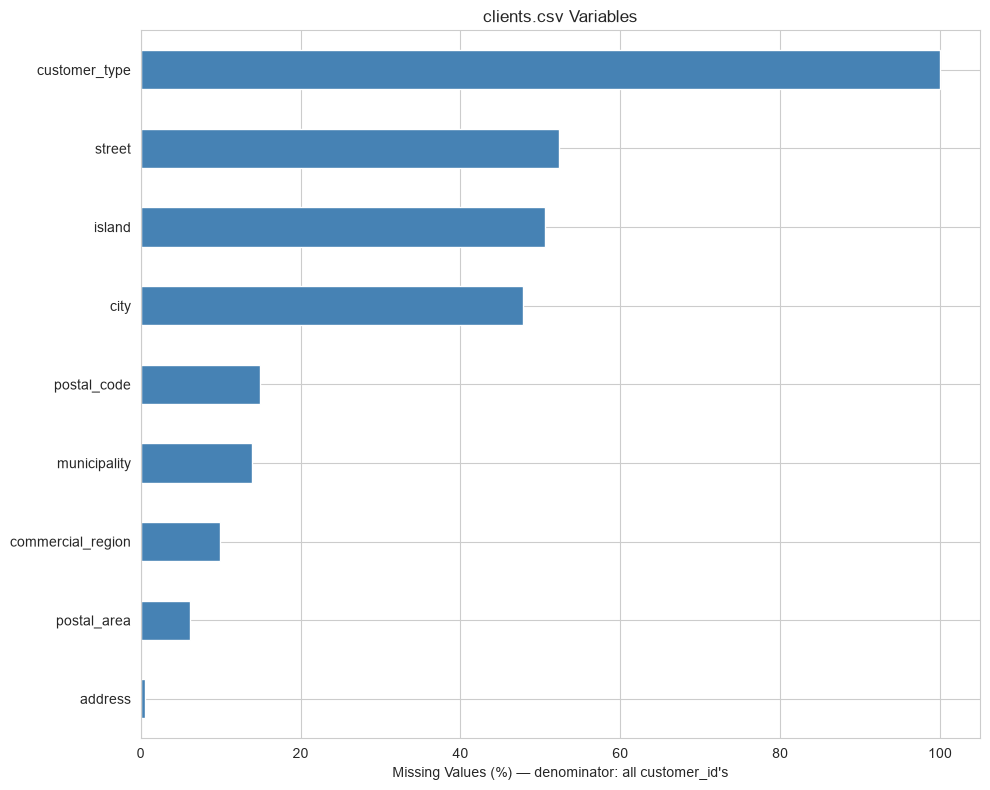

In [31]:
#análise absoluta e percentual de nulos por variável
missing = (
    clients_raw.isna().sum()
    .to_frame("n_missing")
    .assign(pct_missing=lambda x: 100 * x["n_missing"] / len(clients_raw))
    .query("n_missing > 0")
    .sort_values("n_missing", ascending=False)
)
print(missing)



missing["pct_missing"].sort_values().plot.barh(
    figsize=(10, 8), color="steelblue"
)


#gráfico de barras percentagem de nulos por variável
plt.xlabel("Missing Values (%) — denominator: all customer_id's")
plt.title("clients.csv Variables")
plt.tight_layout()
plt.show()

The `customer_type` variable is 100% empty (1,143 rows), it carries no information so being useless. We discovered also that fields such as `street` and `city` have excessive missing values and high cardinality, creating noise and overfitting risk. `island` with 50.6% of missing values reflects business structure: values are missing simply because the customer is on the mainland. Therefore, it could be classified as MNAR (Missing Not at Random).

Vamos agora testar se a existência de missing values afeta, de alguma forma, a taxa de recompra.  

,Variables,Repeat purchase (%),Repeat purchase (with Missing Values %),Difference (p.p.)
0,commercial_region,56.04,34.29,-21.75
2,municipality,56.53,38.25,-18.28
4,postal_area,56.57,41.37,-15.20
5,postal_code,56.43,41.78,-14.65
1,island,51.79,64.00,12.21
6,street,51.96,58.71,6.75
3,city,56.34,55.07,-1.27
7,address,55.92,NaN,NaN


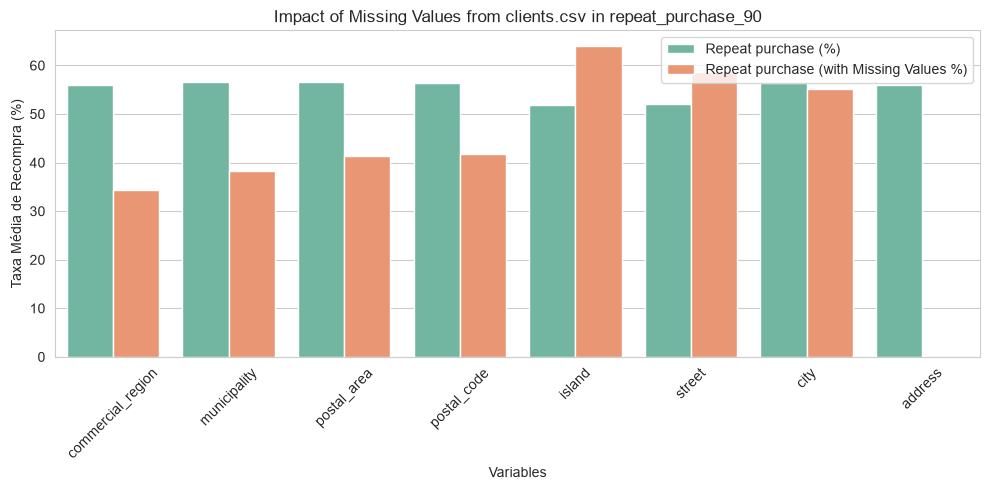

In [52]:

# 1. Cruzar o histórico de compras (train) com o cadastro de clientes
df_merged = train[["customer_id", "repeat_purchase_90d"]].merge(
    clients, on="customer_id", how="left"
)

# 2. Lista de colunas de clientes.csv com valores em falta
cols_com_nulos = [
    col for col in clients.columns 
    if clients[col].isna().sum() > 0 and col != "customer_type"
]

# 3. Calcular a taxa de recompra quando o dado está PREENCHIDO vs quando está NULO
relacao_nulos_target = []

for col in cols_com_nulos:
    # Criar indicador se está nulo na transação
    is_na = df_merged[col].isna()
    
    taxa_com_dado = df_merged.loc[~is_na, "repeat_purchase_90d"].mean() * 100
    taxa_sem_dado = df_merged.loc[is_na, "repeat_purchase_90d"].mean() * 100
    diferenca = taxa_sem_dado - taxa_com_dado
    
    relacao_nulos_target.append({
        "Variables": col,
        "Repeat purchase (%)": round(taxa_com_dado, 2),
        "Repeat purchase (with Missing Values %)": round(taxa_sem_dado, 2),
        "Difference (p.p.)": round(diferenca, 2)
    })

df_relacao = pd.DataFrame(relacao_nulos_target).sort_values(by="Difference (p.p.)", key=abs, ascending=False)
display(df_relacao)


# Gráfico comparativo do impacto da ausência de dados na taxa de recompra
plt.figure(figsize=(10, 5))
df_plot = df_relacao.melt(
    id_vars="Variables", 
    value_vars=["Repeat purchase (%)", "Repeat purchase (with Missing Values %)"],
    var_name="Situation", 
    value_name="Repurchase (%)"
)

sns.barplot(data=df_plot, x="Variables", y="Repurchase (%)", hue="Situation", palette="Set2")
plt.title("Impact of Missing Values from clients.csv in repeat_purchase_90")
plt.xticks(rotation=45)
plt.ylabel("Taxa Média de Recompra (%)")
plt.legend(title="")
plt.tight_layout()
plt.show()

Crossing client-level missingness with `repeat_purchase_90d` reveals strong predictive signals across geographic attributes:

* Mainland vs. Islands (`island` +12.21 p.p.): Missing values in `island` represent mainland customers (a structural missingness pattern). Mainland clients exhibit a significantly higher repeat purchase rate (64.00%) compared to island-based clients (51.79%), driven by lower shipping costs, faster delivery logistics, and easier order placement.   
* Cadastral Completeness (`commercial_region` -21.75 p.p.): Unrecorded territory attributes signal incomplete or informal customer profiles. Customers with missing `commercial_region` show a drop in repeat purchase rate to 34.29% (vs. 56.04% when present).
* Actionable Insight: While missing address details carry clear predictive signal, raw string features (`street`, `city`) introduce excessive cardinality. Instead of keeping noisy address strings, we drop granular fields and capture this signal through clean regional aggregates and binary missingness indicators where appropriate

In [53]:

#número total de missing values e percentagem

#REFAZER!!!!
nulos_por_linha = clients.isna().sum(axis=1)
print(f"Compras com pelo menos um nulo: {nulos_por_linha.gt(0).sum():,} ({nulos_por_linha.gt(0).mean():.1%})")
print(f"Compras completas: {nulos_por_linha.eq(0).sum():,}")
display(nulos_por_linha.value_counts().sort_index().rename_axis("Nulos na linha").to_frame("Rows"))


Compras com pelo menos um nulo: 1,143 (100.0%)
Compras completas: 0


,Rows
Nulos na linha,
1,121
2,388
3,338
4,135
5,72
6,58
7,24
8,5
9,2


In [54]:
#NÃO PERCEBO

linhas_muito_incompletas = nulos_por_linha.eq(36)
print("Compras com 36 campos em falta:", linhas_muito_incompletas.sum())
print("Campos preenchidos nessas linhas (além do índice ID):")
disponibilidade = train.loc[linhas_muito_incompletas].notna().sum()
display(disponibilidade.loc[disponibilidade > 0].to_frame("Disponíveis"))

resumo_incompletude = train.groupby(linhas_muito_incompletas)["repeat_purchase_90d"].agg(
    compras="size", taxa_recompra="mean"
)
resumo_incompletude.index.name = "Tem 36 campos em falta"
display(resumo_incompletude)

Compras com 36 campos em falta: 0
Campos preenchidos nessas linhas (além do índice ID):


IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

### 3.3 Impossible Values

Given that `clientes.csv` consists almost entirely of categorical features, outlier analysis is not applicable. Instead, we focus on verifying impossible values across the numerical attributes (such as `customer_since_year`). Using `describe()`, we aim to check for impossible values that would signal data corruption.

In [146]:
display(clients.drop(columns=["customer_id", "customer_type"], errors="ignore").describe().T.round(2))


print(f"\n{clients_raw["customer_since_year"].value_counts(dropna=False).sort_index()}")

print()
print()
# Ano máximo de compra no train (limite superior plausível)
purchase_dates = pd.to_datetime(train["purchase_date"])
print("Latest purchase year of train.csv:", purchase_dates.dt.year.max())

# O cliente não pode ter começado depois da sua primeira compra
first_purchase_year = purchase_dates.dt.year.groupby(train["customer_id"]).min()
since_year = clients_raw.set_index("customer_id")["customer_since_year"].reindex(first_purchase_year.index)
print("Customers with customer_since_year after first purchase:", (since_year > first_purchase_year).sum())


,count,mean,std,min,25%,50%,75%,max
customer_since_year,1143.0,2017.0,2.97,2015.0,2015.0,2015.0,2018.0,2026.0



customer_since_year
2015    664
2016     53
2017     82
2018     61
2019     47
2020     50
2021     52
2022     43
2023     29
2024     31
2025     18
2026     13
Name: count, dtype: int64


Latest purchase year of train.csv: 2025.0
Customers with customer_since_year after first purchase: 0


Among the numeric columns, only `customer_since_year` carries information: `customer_type` is entirely missing (it is read as numeric only because an empty column is stored as `float64`), and `customer_id` is an identifier, so it was excluded.

 The values range from 2015 to 2026 (inclusive), which is consistent with the period covered by the purchase data, and no customer starts after their first recorded purchase, so no impossible values were found in this variable. However, the distribution is highly concentrated at the minimum: at least half of the customers have `customer_since_year = 2015`. 


 We have also other the maximum being 2026 and the latest purchase year of training set being 2025, so we tested the possible existence of inconsistency.



In [147]:
since = clients_raw["customer_since_year"]
print("Customers with customer_since_year = 2026:", (since == 2026).sum())

ids_train = set(train["customer_id"])
c2026 = clients_raw.loc[since == 2026, "customer_id"]
print("  of which have purchases in train:", c2026.isin(ids_train).sum())

Customers with customer_since_year = 2026: 13
  of which have purchases in train: 0


All 13 customers with `customer_since_year`= 2026 have no purchases in the training set, which is consistent with the latest purchase in `train.csv` being from 2025, so no impossible values were found.

## VER DEPOIS EM CONJUNTO

,Compras
Histórico,
Com histórico,5866
Sem histórico,603
Desconhecido,65


,days_since_previous_purchase,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days
Histórico,,,,,,,
Com histórico,3.29,3.31,7.59,0.0,0.0,10.91,13.81
Desconhecido,100.00,100.00,100.00,100.0,100.0,100.00,100.00
Sem histórico,100.00,100.00,100.00,100.0,100.0,100.00,100.00


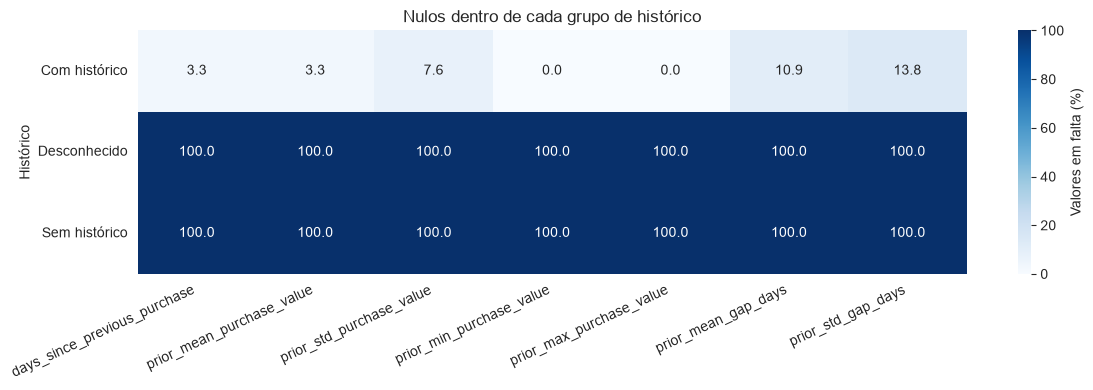

In [148]:
#TRAIN.CSV






colunas_historico = [
    "days_since_previous_purchase", "prior_mean_purchase_value",
    "prior_std_purchase_value", "prior_min_purchase_value",
    "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days",
]
grupo_historico = pd.Series("Contagem inválida", index=train.index, name="Histórico")
grupo_historico.loc[train["prior_purchase_count"].gt(0)] = "Com histórico"
grupo_historico.loc[train["prior_purchase_count"].eq(0)] = "Sem histórico"
grupo_historico.loc[train["prior_purchase_count"].isna()] = "Desconhecido"

nulos_historico = train[colunas_historico].isna().groupby(grupo_historico).mean().mul(100)
display(grupo_historico.value_counts().to_frame("Compras"))
display(nulos_historico.round(2))

plt.figure(figsize=(12, 4))
sns.heatmap(nulos_historico, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "Valores em falta (%)"})
plt.title("Nulos dentro de cada grupo de histórico")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()